# 第7章　動力学的摩擦で軌道減衰を調べる
**完成版 / Chap.6--7分離版 v2.3**

固定したPlummer主銀河の中を動く衛星中心にChandrasekhar動力学的摩擦を加えます。
速度依存力を含むため、時間積分には第1章で学んだRK4を使います。
摩擦は衛星中心にのみ加え、追加実習の質量ゼロの星には直接加えません。
PDFが説明の正本、このNotebookが実装・数値実験の正本です。前章のカーネル状態には依存しません。

In [1]:
from pathlib import Path
from math import erf
import json
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd() / "output" / "chap07"
ROOT.mkdir(parents=True, exist_ok=True)
FIGDIR, DATADIR = ROOT / "figures", ROOT / "data"
FIGDIR.mkdir(exist_ok=True)
DATADIR.mkdir(exist_ok=True)
IN_NOTEBOOK = "get_ipython" in globals()
if IN_NOTEBOOK:
    get_ipython().run_line_magic("matplotlib", "inline")
BLUE, VERMILLION, GREEN, GRAY = "#0072B2", "#D55E00", "#009E73", "#777777"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white"})
KM_S_TO_KPC_GYR = 1.0227121650537077
G = 4.30091e-6 * KM_S_TO_KPC_GYR**2


def save_figure(fig, name):
    fig.savefig(FIGDIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGDIR / f"{name}.png", dpi=160, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)


def to_json(value):
    if isinstance(value, np.ndarray): return value.tolist()
    if isinstance(value, np.generic): return value.item()
    if isinstance(value, dict): return {str(k): to_json(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)): return [to_json(v) for v in value]
    return value

## 0. 前章までから再利用する最小限の関数
円盤の追加実習で必要なCDF、Plummer円運動速度、Plummer加速度、局所円盤の並進だけを再掲します。
第7章の新しい数値算法ではありません。

In [2]:
def check_positive(value, name):
    if isinstance(value, (bool, np.bool_)) or not np.isscalar(value) or not np.isfinite(value) or value <= 0.0:
        raise ValueError(f"{name} must be finite and positive.")


def check_integer(value, name):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < 1:
        raise ValueError(f"{name} must be a positive integer.")


def check_grid(x, values):
    x, values = np.asarray(x, dtype=float), np.asarray(values, dtype=float)
    if x.ndim != 1 or x.size < 2 or values.shape != x.shape: raise ValueError("Nodes and values must be equal-length 1D arrays.")
    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(values)) or np.any(np.diff(x) <= 0.0): raise ValueError("Use finite values and strictly increasing nodes.")
    return x, values


def cumulative_trapezoid(x, values):
    x, values = check_grid(x, values)
    integral = np.zeros_like(x)
    for j in range(len(x) - 1): integral[j + 1] = integral[j] + 0.5 * (values[j] + values[j + 1]) * (x[j + 1] - x[j])
    return integral


def build_radial_cdf(rd, rmax, n_panels):
    check_positive(rd, "rd"); check_positive(rmax, "rmax"); check_integer(n_panels, "n_panels")
    nodes = np.linspace(0.0, rmax, n_panels + 1)
    integral = cumulative_trapezoid(nodes, nodes * np.exp(-nodes / rd))
    cdf = integral / integral[-1]
    if np.any(np.diff(cdf) <= 0.0): raise ValueError("The inverse CDF needs strictly increasing values.")
    return nodes, cdf


def circular_speed_plummer(radius, mass, a):
    radius = np.asarray(radius, dtype=float)
    return np.sqrt(G * mass * radius**2 / (radius**2 + a**2)**1.5)


def make_disk(n_particles, mass, a, rd, rmax, spin, rng, n_panels=4096):
    check_integer(n_particles, "n_particles"); check_positive(mass, "mass"); check_positive(a, "a")
    if isinstance(spin, (bool, np.bool_)) or spin not in (-1, +1): raise ValueError("spin must be +1 or -1.")
    nodes, values = build_radial_cdf(rd, rmax, n_panels)
    uniform = rng.random((n_particles, 2)); radius = np.interp(uniform[:, 0], values, nodes); phi = 2.0 * np.pi * uniform[:, 1]
    vc = circular_speed_plummer(radius, mass, a)
    pos = np.column_stack((radius * np.cos(phi), radius * np.sin(phi)))
    vel = spin * np.column_stack((-vc * np.sin(phi), vc * np.cos(phi)))
    return np.column_stack((pos, vel)), radius, phi


def acceleration_plummer(pos, center, mass, a):
    relative = pos - center; radius2 = np.sum(relative**2, axis=1)
    return -G * mass * relative / (radius2 + a**2)[:, None]**1.5


def place_disk(local_state, center_state):
    placed = local_state.copy(); placed[:, :2] += center_state[:2]; placed[:, 2:] += center_state[2:]
    return placed

## 1. 固定Plummer主銀河と衛星中心
ここからは別のモデルです。主銀河を原点に固定し、衛星中心の軌道だけをRK4で求めます。
基本編の等質量遭遇に摩擦をそのまま足した計算ではありません。
質量比1:10、初期半径20 kpc、1.5 Gyrまでとし、既存の発展用最小モデルを引き継ぎます。
$\rho(r)$と1次元速度分散$\sigma(r)$をPlummer球から与え、局所速度分布をMaxwell分布と近似します。
この速度分布の近似は、Plummer球の厳密な分布関数と同じではありません。

In [3]:
df_params = dict(m_host=1.0e11, a_host=3.0, m_sat=1.0e10, a_sat=1.5,
                 ln_lambda=float(np.log(11.0)), friction=True)
df_r0, df_t_end, df_n_steps = 20.0, 1.50, 1500
df_vc = circular_speed_plummer(df_r0, df_params["m_host"], df_params["a_host"])
df_initial = np.array([[df_r0, 0.0, 0.0, df_vc]])


def check_df_params(params):
    for key in ["m_host", "a_host", "m_sat", "a_sat"]:
        check_positive(params[key], key)
    if isinstance(params["ln_lambda"], (bool, np.bool_)) or not np.isscalar(params["ln_lambda"]) or not np.isfinite(params["ln_lambda"]) or params["ln_lambda"] < 0.0:
        raise ValueError("ln_lambda must be finite and nonnegative.")
    if not isinstance(params["friction"], (bool, np.bool_)):
        raise ValueError("friction must be a boolean.")


def host_density(radius, m_host, a_host):
    return 3.0 * m_host / (4.0 * np.pi * a_host**3) * (1.0 + (radius / a_host)**2)**(-2.5)


def host_sigma(radius, m_host, a_host):
    return np.sqrt(G * m_host / (6.0 * np.sqrt(radius**2 + a_host**2)))


def maxwell_factor_over_x3(x):
    """[erf(x)-2x exp(-x^2)/sqrt(pi)]/x^3 の連続な低速極限を使います。"""
    if not np.isfinite(x) or x < 0.0:
        raise ValueError("x must be finite and nonnegative.")
    if x < 1.0e-3:
        return 4.0 / (3.0 * np.sqrt(np.pi)) * (1.0 - 0.6 * x**2 + 3.0 * x**4 / 14.0)
    return (erf(x) - 2.0 * x * np.exp(-x*x) / np.sqrt(np.pi)) / x**3


def chandrasekhar_acceleration(pos, vel, params):
    radius, speed = np.linalg.norm(pos), np.linalg.norm(vel)
    rho = host_density(radius, params["m_host"], params["a_host"])
    sigma = host_sigma(radius, params["m_host"], params["a_host"])
    scale_v = np.sqrt(2.0) * sigma
    x = speed / scale_v
    ### BEGIN SOLUTION
    gamma = 4.0 * np.pi * G**2 * params["m_sat"] * rho * params["ln_lambda"]
    gamma *= maxwell_factor_over_x3(x) / scale_v**3
    return -gamma * vel
    ### END SOLUTION


def df_center_rhs(t, state, params):
    if state.shape != (1, 4):
        raise ValueError("The center-only RHS requires shape (1, 4).")
    pos, vel = state[0, :2], state[0, 2:]
    acc = acceleration_plummer(pos[None, :], np.zeros(2), params["m_host"], params["a_host"])[0]
    if params["friction"]:
        acc += chandrasekhar_acceleration(pos, vel, params)
    return np.array([[vel[0], vel[1], acc[0], acc[1]]])


def rk4_step(rhs, t, state, dt, params):
    k1 = rhs(t, state, params)
    k2 = rhs(t + 0.5 * dt, state + 0.5 * dt * k1, params)
    k3 = rhs(t + 0.5 * dt, state + 0.5 * dt * k2, params)
    k4 = rhs(t + dt, state + dt * k3, params)
    return state + dt * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0


def integrate_rk4(rhs, initial, duration, n_steps, params, save_every=1):
    check_df_params(params)
    check_positive(duration, "duration")
    check_integer(n_steps, "n_steps")
    check_integer(save_every, "save_every")
    state = np.array(initial, dtype=float, copy=True)
    if state.ndim != 2 or state.shape[1] != 4 or len(state) < 1 or not np.all(np.isfinite(state)):
        raise ValueError("initial must be finite with shape (N, 4).")
    steps = np.arange(0, n_steps + 1, save_every)
    if steps[-1] != n_steps:
        steps = np.append(steps, n_steps)
    dt = duration / n_steps
    history = np.empty((len(steps), len(state), 4))
    history[0] = state
    j = 1
    for n in range(n_steps):
        state = rk4_step(rhs, n * dt, state, dt, params)
        if not np.all(np.isfinite(state)):
            raise FloatingPointError("Non-finite RK4 state; revise model and time step.")
        if n + 1 == steps[j]:
            history[j] = state
            j += 1
    return steps * dt, history

check_df_params(df_params)
df_t, df_h = integrate_rk4(df_center_rhs, df_initial, df_t_end, df_n_steps, df_params)
no_df_params = dict(df_params, friction=False)
_, no_df_h = integrate_rk4(df_center_rhs, df_initial, df_t_end, df_n_steps, no_df_params)

## 2. 半径・エネルギー・角運動量
衛星の比エネルギーを $\varepsilon=v^2/2+\Phi_{\rm host}$、比角運動量を $\ell_z=xv_y-yv_x$ とします。
摩擦ありでは $d\varepsilon/dt=\boldsymbol v\cdot\boldsymbol a_{\rm df}\leq0$ です。
主銀河への反作用は計算しないので、主銀河と衛星を合わせた全エネルギー収支を追跡するモデルではありません。
衛星の運動エネルギー単独や速度の大きさが単調に減るとは限りません。深いポテンシャルへ移るからです。

R(1.5 Gyr): no friction=19.999999999; friction=7.798195542 kpc
No-friction E/L relative errors: 6.4207272281179655e-12 3.354809577595067e-12
With friction: E/E0_abs, L/L0, work residual = -2.7143781487933545 0.5625247049607787 1.2277259178857625e-05


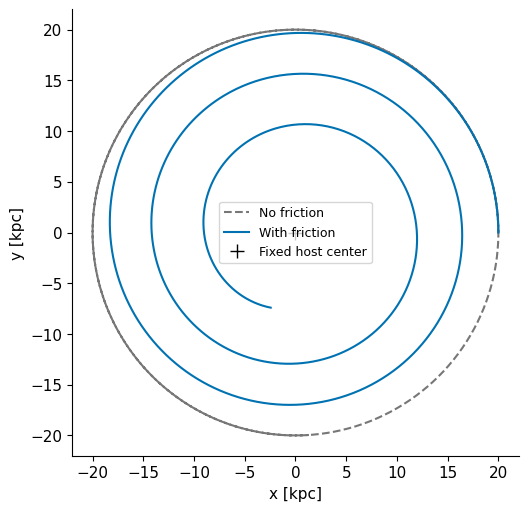

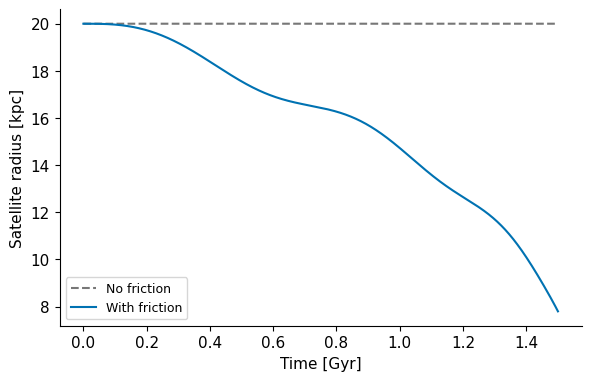

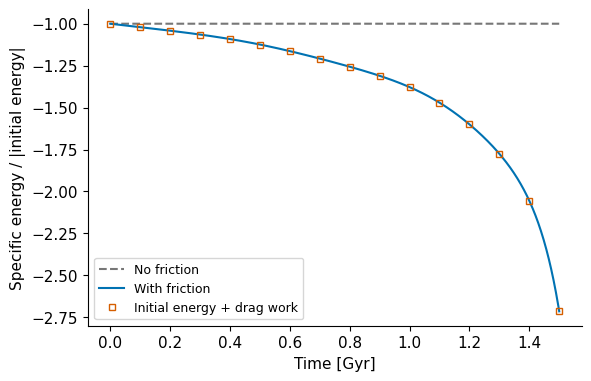

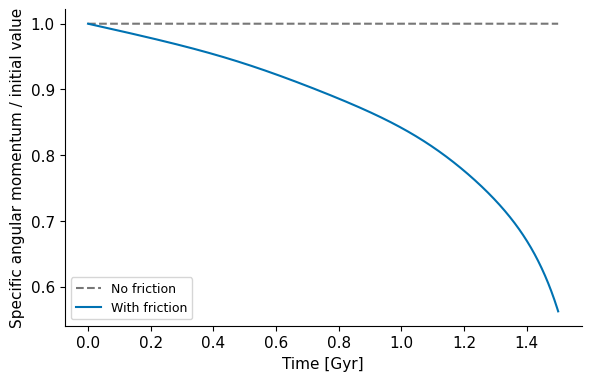

In [4]:
def df_diagnostics(history, params):
    pos, vel = history[:, 0, :2], history[:, 0, 2:]
    radius = np.linalg.norm(pos, axis=1)
    potential = -G * params["m_host"] / np.sqrt(radius**2 + params["a_host"]**2)
    energy = 0.5 * np.sum(vel**2, axis=1) + potential
    angular = pos[:, 0] * vel[:, 1] - pos[:, 1] * vel[:, 0]
    power = np.zeros(len(history))
    if params["friction"]:
        for j in range(len(history)):
            power[j] = np.dot(vel[j], chandrasekhar_acceleration(pos[j], vel[j], params))
    return radius, energy, angular, power

r_df, e_df, l_df, power_df = df_diagnostics(df_h, df_params)
r_no, e_no, l_no, _ = df_diagnostics(no_df_h, no_df_params)
work_df = cumulative_trapezoid(df_t, power_df)
work_residual = np.max(np.abs(e_df - e_df[0] - work_df)) / abs(e_df[0])
print(f"R(1.5 Gyr): no friction={r_no[-1]:.9f}; friction={r_df[-1]:.9f} kpc")
print("No-friction E/L relative errors:", np.max(np.abs(e_no-e_no[0]))/abs(e_no[0]), np.max(np.abs(l_no-l_no[0]))/abs(l_no[0]))
print("With friction: E/E0_abs, L/L0, work residual =", e_df[-1]/abs(e_df[0]), l_df[-1]/l_df[0], work_residual)

fig, ax = plt.subplots(figsize=(5.3, 5.0), layout="constrained")
ax.plot(no_df_h[:, 0, 0], no_df_h[:, 0, 1], color=GRAY, ls="--", label="No friction")
ax.plot(df_h[:, 0, 0], df_h[:, 0, 1], color=BLUE, label="With friction")
ax.plot(0.0, 0.0, "+", color="black", ms=10, label="Fixed host center")
ax.set(xlabel="x [kpc]", ylabel="y [kpc]")
ax.set_aspect("equal")
ax.legend(fontsize=9)
save_figure(fig, "ch07_df_orbit")

for label, y0, y1, ylabel, fname in [
    ("radius", r_no, r_df, "Satellite radius [kpc]", "ch07_df_radius"),
    ("energy", e_no/abs(e_no[0]), e_df/abs(e_df[0]), "Specific energy / |initial energy|", "ch07_df_energy"),
    ("angular", l_no/l_no[0], l_df/l_df[0], "Specific angular momentum / initial value", "ch07_df_angular")]:
    fig, ax = plt.subplots(figsize=(5.8, 3.7), layout="constrained")
    ax.plot(df_t, y0, color=GRAY, ls="--", label="No friction")
    ax.plot(df_t, y1, color=BLUE, label="With friction")
    if label == "energy":
        ids = np.arange(0, len(df_t), 100)
        ax.plot(df_t[ids], (e_df[0]+work_df[ids])/abs(e_df[0]), "s", ms=4, mfc="none", color=VERMILLION, label="Initial energy + drag work")
    ax.set(xlabel="Time [Gyr]", ylabel=ylabel)
    ax.legend(fontsize=9)
    save_figure(fig, fname)
np.savetxt(DATADIR / "df_history.csv", np.column_stack((df_t, r_no, r_df, e_no, e_df, l_no, l_df, work_df)), delimiter=",", header="t_Gyr,r_no,r_df,e_no,e_df,l_no,l_df,drag_work", comments="")

## 3. 摩擦ありでも刻み試験を行う
4,2,1,0.5 Myrで積分し、0.5 Myrを含めて隣接する解を同じ時刻で比較します。
位置の差は真の解との誤差ではありません。十分細かい範囲では4次法の差の比が約16になることを調べます。
摩擦の仕事を**後処理の台形則**で積分した残差も保存します。この残差には台形則の2次誤差が含まれます。

In [5]:
df_resolutions, df_resolution_rows, df_self_rows = [], [], []
for count in [375, 750, 1500, 3000]:
    tt, hh = integrate_rk4(df_center_rhs, df_initial, df_t_end, count, df_params)
    rr, ee, ll, pp = df_diagnostics(hh, df_params)
    ww = cumulative_trapezoid(tt, pp)
    balance = np.max(np.abs(ee-ee[0]-ww)) / abs(ee[0])
    df_resolutions.append(hh)
    df_resolution_rows.append([count, df_t_end/count, rr[-1], balance])
for j in range(len(df_resolutions)-1):
    diff = df_resolutions[j][:, 0, :2] - df_resolutions[j+1][::2, 0, :2]
    df_self_rows.append([df_resolution_rows[j][0], df_resolution_rows[j+1][0], np.max(np.linalg.norm(diff, axis=1))/df_r0])
df_ratios = np.array(df_self_rows)[:-1, 2] / np.array(df_self_rows)[1:, 2]
print("RK4 refinement [steps, dt_Gyr, r_final, work_balance]:", df_resolution_rows)
print("Adjacent position differences:", df_self_rows, "; ratios:", df_ratios)

lambda_rows = []
for log_lambda in [1.0, 2.0, float(np.log(11.0))]:
    params = dict(df_params, ln_lambda=log_lambda)
    tt, hh = integrate_rk4(df_center_rhs, df_initial, df_t_end, df_n_steps, params)
    lambda_rows.append([log_lambda, np.linalg.norm(hh[-1, 0, :2])])
print("Coulomb logarithm [lnLambda, r_final]:", lambda_rows)

RK4 refinement [steps, dt_Gyr, r_final, work_balance]: [[375, 0.004, np.float64(7.798145298328891), np.float64(0.00019096601587331087)], [750, 0.002, np.float64(7.798192728378772), np.float64(4.88580447138777e-05)], [1500, 0.001, np.float64(7.798195541888207), np.float64(1.2277259178857625e-05)], [3000, 0.0005, np.float64(7.798195712878658), np.float64(3.0730043893136976e-06)]]
Adjacent position differences: [[375, 750, np.float64(6.2865252604080975e-06)], [750, 1500, np.float64(3.7157412269215483e-07)], [1500, 3000, np.float64(2.254254639491768e-08)]] ; ratios: [16.91863043 16.48323646]


Coulomb logarithm [lnLambda, r_final]: [[1.0, np.float64(17.06340732780335)], [2.0, np.float64(12.143811649915973)], [2.3978952727983707, np.float64(7.798195541888207)]]


## 4. 衛星の周りの星も動かす
衛星は $a_{\rm sat}=1.5$ kpc のPlummer場として、500個のテスト粒子に重力を与えます。
初期分布は $R_d=1$ kpc、$R_{\max}=4$ kpcです。
先頭1行が衛星中心、残りが星です。主銀河は原点に固定し、配列に可動中心として入れません。
RK4の各段階で衛星と星を同時に予測します。星には摩擦を直接加えません。
粒子が遠ざかっても衛星の $M_{\rm sat},a_{\rm sat}$ は変わりません。自己無撞着な質量損失ではありません。

Satellite tracer comparison: max/Rd, RMS/Rd = 0.0006302304875922364 7.695044711907144e-06


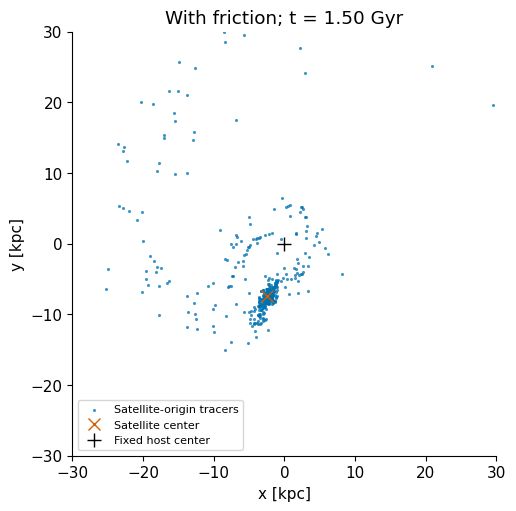

In [6]:
def df_tracer_rhs(t, state, params):
    deriv = np.empty_like(state)
    deriv[:, :2] = state[:, 2:]
    deriv[0] = df_center_rhs(t, state[:1], params)[0]
    pos = state[1:, :2]
    ### BEGIN SOLUTION
    deriv[1:, 2:] = acceleration_plummer(pos, np.zeros(2), params["m_host"], params["a_host"])
    deriv[1:, 2:] += acceleration_plummer(pos, state[0, :2], params["m_sat"], params["a_sat"])
    ### END SOLUTION
    return deriv

local_sat, _, _ = make_disk(500, df_params["m_sat"], df_params["a_sat"], 1.0, 4.0, 1, np.random.default_rng(42))
tracer_initial = np.vstack((df_initial, place_disk(local_sat, df_initial[0])))
# 星の軌道も見る追加実習では中心だけより細かい0.25 Myrを使います。
sat_times, sat_history = integrate_rk4(df_tracer_rhs, tracer_initial, df_t_end, 6000, df_params, 40)
_, sat_finer = integrate_rk4(df_tracer_rhs, tracer_initial, df_t_end, 12000, df_params, 80)
sat_diff = sat_history[:, 1:, :2] - sat_finer[:, 1:, :2]
sat_maxdiff = np.max(np.linalg.norm(sat_diff, axis=2))
sat_rmsdiff = np.sqrt(np.mean(np.sum(sat_diff**2, axis=2)))
_, same_center = integrate_rk4(df_center_rhs, df_initial, df_t_end, 6000, df_params, 40)
assert np.array_equal(sat_history[:, :1], same_center)
print("Satellite tracer comparison: max/Rd, RMS/Rd =", sat_maxdiff, sat_rmsdiff)
fig, ax = plt.subplots(figsize=(5.3, 5.0), layout="constrained")
final_sat = sat_history[-1]
ax.scatter(final_sat[1:, 0], final_sat[1:, 1], s=5, color=BLUE, alpha=0.75, linewidths=0, label="Satellite-origin tracers")
ax.plot(final_sat[0, 0], final_sat[0, 1], "x", color=VERMILLION, ms=8, label="Satellite center")
ax.plot(0.0, 0.0, "+", color="black", ms=10, label="Fixed host center")
ax.set(xlabel="x [kpc]", ylabel="y [kpc]", xlim=(-30, 30), ylim=(-30, 30), title="With friction; t = 1.50 Gyr")
ax.set_aspect("equal")
ax.legend(fontsize=8)
save_figure(fig, "ch07_satellite")
np.savez_compressed(DATADIR / "satellite_snapshots.npz", times=sat_times[::50], state=sat_history[::50])

## 5. 記録と課題
**確認：** 摩擦あり・なしの軌道と保存量を比較してください。
**応用：** 時間刻みとCoulomb対数を別々に変更し、数値精度と物理モデルの変更を区別してください。
**発展：** 衛星の星を動かし、質量損失を自己無撞着に扱っていないことが結論へ与える制限を説明してください。

In [7]:
validation = dict(version="2.3", numpy_version=np.__version__, df_params=df_params,
                  df_final_radius=r_df[-1], no_df_final_radius=r_no[-1],
                  df_final_energy_ratio=e_df[-1]/abs(e_df[0]), df_final_angular_ratio=l_df[-1]/l_df[0],
                  no_df_energy_error=np.max(np.abs(e_no-e_no[0]))/abs(e_no[0]),
                  no_df_angular_error=np.max(np.abs(l_no-l_no[0]))/abs(l_no[0]), work_residual=work_residual,
                  df_resolution=df_resolution_rows, df_self=df_self_rows, df_ratios=df_ratios,
                  lambda_rows=lambda_rows, sat_maxdiff=sat_maxdiff, sat_rmsdiff=sat_rmsdiff)
(DATADIR / "validation.json").write_text(json.dumps(to_json(validation), ensure_ascii=False, indent=2), encoding="utf-8")
assert np.max(power_df) <= 0.0
assert np.max(np.diff(e_df)) < 0.0
assert 7.0 < r_df[-1] < 9.0
print("Chapter 7 dynamical-friction runs completed. Validation and numerical tables saved in", DATADIR)

Chapter 7 dynamical-friction runs completed. Validation and numerical tables saved in output/chap07/data
